In [1]:
from google.colab import files

uploaded = files.upload()

Saving bigmart.xls to bigmart.xls


In [2]:
!pip install pandas numpy matplotlib seaborn openpyxl scikit-learn

In [3]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

import os

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

sns.set_theme(style="whitegrid")

print("All libraries imported successfully!")

All libraries imported successfully!


In [11]:
df = pd.read_csv("/content/bigmart.xls")

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [13]:
df.head(10)

,Item_Identifier,Item_Weight,Item_Fat_Content,Item_Visibility,Item_Type,Item_MRP,Outlet_Identifier,Outlet_Establishment_Year,Outlet_Size,Outlet_Location_Type,Outlet_Type,Item_Outlet_Sales
0,FDA15,9.300,Low Fat,0.016047,Dairy,249.8092,OUT049,1999,Medium,Tier 1,Supermarket Type1,3735.1380
1,DRC01,5.920,Regular,0.019278,Soft Drinks,48.2692,OUT018,2009,Medium,Tier 3,Supermarket Type2,443.4228
2,FDN15,17.500,Low Fat,0.016760,Meat,141.6180,OUT049,1999,Medium,Tier 1,Supermarket Type1,2097.2700
3,FDX07,19.200,Regular,0.000000,Fruits and Vegetables,182.0950,OUT010,1998,NaN,Tier 3,Grocery Store,732.3800
4,NCD19,8.930,Low Fat,0.000000,Household,53.8614,OUT013,1987,High,Tier 3,Supermarket Type1,994.7052
5,FDP36,10.395,Regular,0.000000,Baking Goods,51.4008,OUT018,2009,Medium,Tier 3,Supermarket Type2,556.6088
6,FDO10,13.650,Regular,0.012741,Snack Foods,57.6588,OUT013,1987,High,Tier 3,Supermarket Type1,343.5528
7,FDP10,NaN,Low Fat,0.127470,Snack Foods,107.7622,OUT027,1985,Medium,Tier 3,Supermarket Type3,4022.7636
8,FDH17,16.200,Regular,0.016687,Frozen Foods,96.9726,OUT045,2002,NaN,Tier 2,Supermarket Type1,1076.5986
9,FDU28,19.200,Regular,0.094450,Frozen Foods,187.8214,OUT017,2007,NaN,Tier 2,Supermarket Type1,4710.5350


In [22]:
categorical_columns = df.select_dtypes(
    include="object"
).columns

for column in categorical_columns:

    print("\nColumn:", column)

    print(df[column].value_counts(dropna=False))


Column: Item_Identifier
Item_Identifier
FDW13    10
FDG33    10
FDX31     9
FDT07     9
NCY18     9
         ..
FDO33     1
FDK57     1
FDT35     1
FDN52     1
FDE52     1
Name: count, Length: 1559, dtype: int64

Column: Item_Fat_Content
Item_Fat_Content
Low Fat    5089
Regular    2889
LF          316
reg         117
low fat     112
Name: count, dtype: int64

Column: Item_Type
Item_Type
Fruits and Vegetables    1232
Snack Foods              1200
Household                 910
Frozen Foods              856
Dairy                     682
Canned                    649
Baking Goods              648
Health and Hygiene        520
Soft Drinks               445
Meat                      425
Breads                    251
Hard Drinks               214
Others                    169
Starchy Foods             148
Breakfast                 110
Seafood                    64
Name: count, dtype: int64

Column: Outlet_Identifier
Outlet_Identifier
OUT027    935
OUT013    932
OUT035    930
OUT049    930
OU

In [23]:
numerical_columns = df.select_dtypes(
    include=np.number
).columns

print(numerical_columns.tolist())

['Item_Weight', 'Item_Visibility', 'Item_MRP', 'Outlet_Establishment_Year', 'Item_Outlet_Sales']


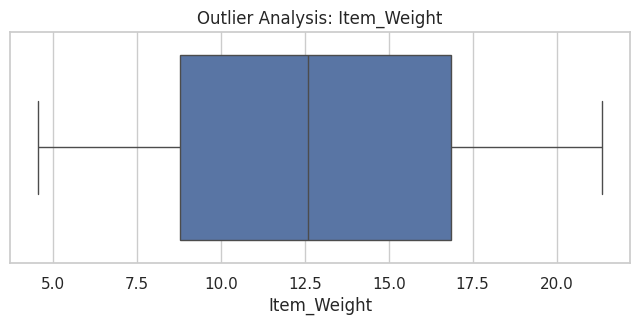

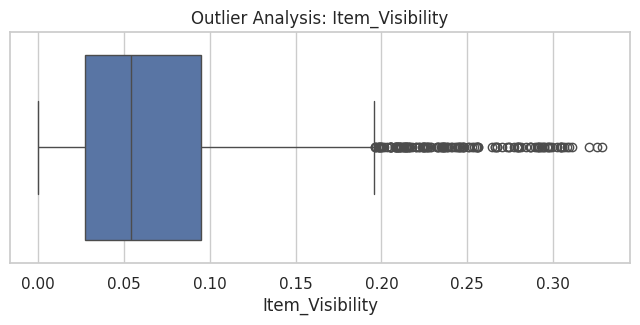

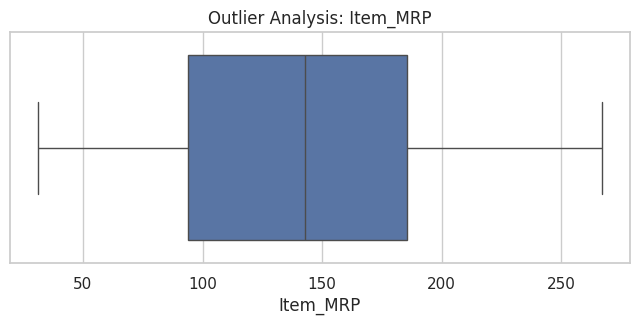

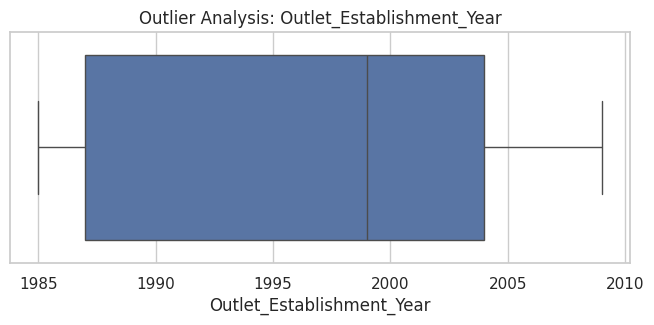

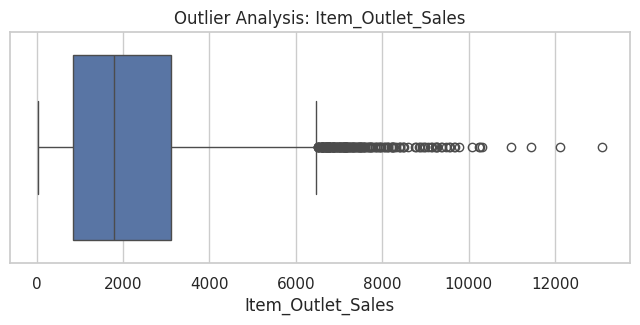

In [24]:
for column in numerical_columns:

    plt.figure(figsize=(8, 3))

    sns.boxplot(x=df[column])

    plt.title(f"Outlier Analysis: {column}")

    plt.show()

In [25]:
outlier_results = []

for column in numerical_columns:

    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = (
        (df[column] < lower_bound) |
        (df[column] > upper_bound)
    )

    outlier_results.append({
        "Column": column,
        "Lower_Bound": lower_bound,
        "Upper_Bound": upper_bound,
        "Outlier_Count": outliers.sum(),
        "Outlier_Percentage": round(
            outliers.mean() * 100, 2
        )
    })

outlier_report = pd.DataFrame(outlier_results)

display(outlier_report)

,Column,Lower_Bound,Upper_Bound,Outlier_Count,Outlier_Percentage
0,Item_Weight,-3.340625,28.964375,0,0.00
1,Item_Visibility,-0.074404,0.195979,144,1.69
2,Item_MRP,-43.899300,323.369500,0,0.00
3,Outlet_Establishment_Year,1961.500000,2029.500000,0,0.00
4,Item_Outlet_Sales,-2566.326100,6501.869900,186,2.18


In [26]:
clean_df = df.copy()

print("Cleaning copy created successfully!")

Cleaning copy created successfully!


In [27]:
clean_df["Item_Weight"] = clean_df.groupby(
    "Item_Identifier"
)["Item_Weight"].transform(
    lambda x: x.fillna(x.median())
)

clean_df["Item_Weight"] = clean_df["Item_Weight"].fillna(
    clean_df["Item_Weight"].median()
)

In [28]:
outlet_size_map = (
    clean_df.groupby("Outlet_Identifier")["Outlet_Size"]
    .agg(lambda x: x.mode().iloc[0] if not x.mode().empty else np.nan)
)

clean_df["Outlet_Size"] = clean_df["Outlet_Size"].fillna(
    clean_df["Outlet_Identifier"].map(outlet_size_map)
)

In [29]:
group_mode = clean_df.groupby(
    ["Outlet_Type", "Outlet_Location_Type"]
)["Outlet_Size"].transform(
    lambda x: x.mode().iloc[0] if not x.mode().empty else np.nan
)

clean_df["Outlet_Size"] = clean_df["Outlet_Size"].fillna(
    group_mode
)

In [30]:
clean_df["Outlet_Size"] = clean_df["Outlet_Size"].fillna("Unknown")

In [31]:
clean_df["Item_Fat_Content"] = (
    clean_df["Item_Fat_Content"]
    .astype("string")
    .str.strip()
    .str.lower()
)

clean_df["Item_Fat_Content"] = (
    clean_df["Item_Fat_Content"]
    .replace({
        "lf": "Low Fat",
        "low fat": "Low Fat",
        "reg": "Regular",
        "regular": "Regular"
    })
)

In [32]:
print(
    clean_df["Item_Fat_Content"].value_counts(
        dropna=False
    )
)

Item_Fat_Content
Low Fat    5517
Regular    3006
Name: count, dtype: Int64


In [33]:
print(
    "Zero visibility values:",
    (clean_df["Item_Visibility"] == 0).sum()
)

Zero visibility values: 526


In [34]:
zero_visibility = clean_df["Item_Visibility"] == 0

category_median = clean_df.groupby(
    "Item_Type"
)["Item_Visibility"].transform("median")

clean_df.loc[
    zero_visibility,
    "Item_Visibility"
] = category_median[zero_visibility]

In [35]:
numeric_columns = [
    "Item_Weight",
    "Item_Visibility",
    "Item_MRP",
    "Item_Outlet_Sales"
]

for column in numeric_columns:

    clean_df[column] = pd.to_numeric(
        clean_df[column],
        errors="coerce"
    )

In [39]:
print("Missing values after cleaning:")

print(clean_df.isnull().sum())

Missing values after cleaning:
Item_Identifier              0
Item_Weight                  0
Item_Fat_Content             0
Item_Visibility              0
Item_Type                    0
Item_MRP                     0
Outlet_Identifier            0
Outlet_Establishment_Year    0
Outlet_Size                  0
Outlet_Location_Type         0
Outlet_Type                  0
Item_Outlet_Sales            0
dtype: int64


In [40]:
print(
    "Duplicates after cleaning:",
    clean_df.duplicated().sum()
)

Duplicates after cleaning: 0


In [41]:
comparison = pd.DataFrame({
    "Metric": [
        "Number of Rows",
        "Number of Columns",
        "Missing Values",
        "Duplicate Rows"
    ],

    "Before Cleaning": [
        df.shape[0],
        df.shape[1],
        df.isnull().sum().sum(),
        df.duplicated().sum()
    ],

    "After Cleaning": [
        clean_df.shape[0],
        clean_df.shape[1],
        clean_df.isnull().sum().sum(),
        clean_df.duplicated().sum()
    ]
})

display(comparison)

,Metric,Before Cleaning,After Cleaning
0,Number of Rows,8523,8523
1,Number of Columns,12,12
2,Missing Values,3873,0
3,Duplicate Rows,0,0


In [42]:
final_quality_report = pd.DataFrame({
    "Column": clean_df.columns,

    "Data_Type": [
        str(clean_df[col].dtype)
        for col in clean_df.columns
    ],

    "Missing_Count": [
        clean_df[col].isnull().sum()
        for col in clean_df.columns
    ],

    "Missing_Percentage": [
        round(clean_df[col].isnull().mean() * 100, 2)
        for col in clean_df.columns
    ],

    "Unique_Values": [
        clean_df[col].nunique()
        for col in clean_df.columns
    ]
})

display(final_quality_report)

,Column,Data_Type,Missing_Count,Missing_Percentage,Unique_Values
0,Item_Identifier,category,0,0.0,1559
1,Item_Weight,float64,0,0.0,415
2,Item_Fat_Content,category,0,0.0,2
3,Item_Visibility,float64,0,0.0,7890
4,Item_Type,category,0,0.0,16
5,Item_MRP,float64,0,0.0,5938
6,Outlet_Identifier,category,0,0.0,10
7,Outlet_Establishment_Year,Int64,0,0.0,9
8,Outlet_Size,category,0,0.0,4
9,Outlet_Location_Type,category,0,0.0,3


In [43]:
clean_df["Item_MRP_Band"] = pd.cut(
    clean_df["Item_MRP"],
    bins=[
        -np.inf,
        70,
        140,
        200,
        np.inf
    ],
    labels=[
        "Low Price",
        "Medium Price",
        "High Price",
        "Very High Price"
    ]
)

print(clean_df["Item_MRP_Band"].value_counts())

Item_MRP_Band
High Price         2964
Medium Price       2778
Very High Price    1440
Low Price          1341
Name: count, dtype: int64


In [44]:
clean_df.to_excel(
    "bigmart_Cleaned.xlsx",
    index=False
)

print("Cleaned Excel file saved successfully!")

Cleaned Excel file saved successfully!


In [45]:
clean_df.to_csv(
    "bigmart_Cleaned.csv",
    index=False
)

In [47]:
from google.colab import files

files.download("bigmart_Cleaned.xlsx")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [48]:
files.download("bigmart_Cleaned.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [36]:
categorical_columns = [
    "Item_Identifier",
    "Item_Fat_Content",
    "Item_Type",
    "Outlet_Identifier",
    "Outlet_Size",
    "Outlet_Location_Type",
    "Outlet_Type"
]

for column in categorical_columns:

    clean_df[column] = clean_df[column].astype("category")

In [37]:
clean_df["Outlet_Establishment_Year"] = (
    clean_df["Outlet_Establishment_Year"].astype("Int64")
)

In [38]:
print(
    "Negative sales:",
    (clean_df["Item_Outlet_Sales"] < 0).sum()
)

print(
    "Negative product prices:",
    (clean_df["Item_MRP"] < 0).sum()
)

Negative sales: 0
Negative product prices: 0


In [14]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Number of rows: 8523
Number of columns: 12


In [15]:
print(df.columns.tolist())

['Item_Identifier', 'Item_Weight', 'Item_Fat_Content', 'Item_Visibility', 'Item_Type', 'Item_MRP', 'Outlet_Identifier', 'Outlet_Establishment_Year', 'Outlet_Size', 'Outlet_Location_Type', 'Outlet_Type', 'Item_Outlet_Sales']


In [16]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8523 entries, 0 to 8522
Data columns (total 12 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Item_Identifier            8523 non-null   object 
 1   Item_Weight                7060 non-null   float64
 2   Item_Fat_Content           8523 non-null   object 
 3   Item_Visibility            8523 non-null   float64
 4   Item_Type                  8523 non-null   object 
 5   Item_MRP                   8523 non-null   float64
 6   Outlet_Identifier          8523 non-null   object 
 7   Outlet_Establishment_Year  8523 non-null   int64  
 8   Outlet_Size                6113 non-null   object 
 9   Outlet_Location_Type       8523 non-null   object 
 10  Outlet_Type                8523 non-null   object 
 11  Item_Outlet_Sales          8523 non-null   float64
dtypes: float64(4), int64(1), object(7)
memory usage: 799.2+ KB


In [17]:
df.describe()

,Item_Weight,Item_Visibility,Item_MRP,Outlet_Establishment_Year,Item_Outlet_Sales
count,7060.000000,8523.000000,8523.000000,8523.000000,8523.000000
mean,12.857645,0.066132,140.992782,1997.831867,2181.288914
std,4.643456,0.051598,62.275067,8.371760,1706.499616
min,4.555000,0.000000,31.290000,1985.000000,33.290000
25%,8.773750,0.026989,93.826500,1987.000000,834.247400
50%,12.600000,0.053931,143.012800,1999.000000,1794.331000
75%,16.850000,0.094585,185.643700,2004.000000,3101.296400
max,21.350000,0.328391,266.888400,2009.000000,13086.964800


In [18]:
df.describe(include="object")

,Item_Identifier,Item_Fat_Content,Item_Type,Outlet_Identifier,Outlet_Size,Outlet_Location_Type,Outlet_Type
count,8523,8523,8523,8523,6113,8523,8523
unique,1559,5,16,10,3,3,4
top,FDW13,Low Fat,Fruits and Vegetables,OUT027,Medium,Tier 3,Supermarket Type1
freq,10,5089,1232,935,2793,3350,5577


In [19]:
missing_count = df.isnull().sum()

missing_percentage = (
    df.isnull().sum() / len(df) * 100
)

missing_report = pd.DataFrame({
    "Missing_Count": missing_count,
    "Missing_Percentage": missing_percentage.round(2)
})

missing_report = missing_report.sort_values(
    by="Missing_Count",
    ascending=False
)

display(missing_report)

,Missing_Count,Missing_Percentage
Outlet_Size,2410,28.28
Item_Weight,1463,17.17
Item_Fat_Content,0,0.00
Item_Identifier,0,0.00
Item_Visibility,0,0.00
Item_Type,0,0.00
Outlet_Identifier,0,0.00
Item_MRP,0,0.00
Outlet_Establishment_Year,0,0.00
Outlet_Location_Type,0,0.00


In [20]:
print("Number of duplicate rows:", df.duplicated().sum())

Number of duplicate rows: 0


In [21]:
data_types = pd.DataFrame({
    "Column": df.columns,
    "Data_Type": df.dtypes.astype(str).values
})

display(data_types)

,Column,Data_Type
0,Item_Identifier,object
1,Item_Weight,float64
2,Item_Fat_Content,object
3,Item_Visibility,float64
4,Item_Type,object
5,Item_MRP,float64
6,Outlet_Identifier,object
7,Outlet_Establishment_Year,int64
8,Outlet_Size,object
9,Outlet_Location_Type,object
